<a href="https://colab.research.google.com/github/cassie22072006/ai-ml/blob/main/lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Data Preparation and Preprocessing
We will first import the necessary libraries and create a synthetic representation of the Stroke Dataset so the entire notebook can execute smoothly.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Create a synthetic dataset mimicking a standard Stroke Dataset
np.random.seed(42)
n_samples = 1000
data = {
    'gender': np.random.choice(['Male', 'Female'], size=n_samples),
    'age': np.random.randint(18, 90, size=n_samples),
    'hypertension': np.random.choice([0, 1], size=n_samples, p=[0.85, 0.15]),
    'heart_disease': np.random.choice([0, 1], size=n_samples, p=[0.9, 0.1]),
    'ever_married': np.random.choice(['Yes', 'No'], size=n_samples),
    'work_type': np.random.choice(['Private', 'Self-employed', 'Govt_job', 'children'], size=n_samples),
    'Residence_type': np.random.choice(['Urban', 'Rural'], size=n_samples),
    'avg_glucose_level': np.random.uniform(55, 270, size=n_samples),
    'bmi': np.random.uniform(15, 45, size=n_samples),
    'smoking_status': np.random.choice(['formerly smoked', 'never smoked', 'smokes', 'Unknown'], size=n_samples),
    'stroke': np.random.choice([0, 1], size=n_samples, p=[0.95, 0.05])
}

df = pd.DataFrame(data)
display(df.head())

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,80,0,0,No,Self-employed,Urban,255.585674,37.167914,Unknown,0
1,Female,34,0,0,Yes,children,Rural,181.100033,15.875097,never smoked,0
2,Male,50,0,0,Yes,children,Rural,168.107741,31.237146,never smoked,0
3,Male,46,0,0,No,Private,Urban,218.251834,16.587223,Unknown,0
4,Male,30,0,0,No,Self-employed,Rural,208.223108,36.034327,never smoked,0


### 2. Feature Engineering & Scaling
We split the data and build a column transformer to scale numerical variables and one-hot encode categorical features.

In [7]:
X = df.drop(columns=['stroke'])
y = df['stroke']

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Define Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fit and transform
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Processed Train dimensions: {X_train_processed.shape}")

Processed Train dimensions: (800, 14)


### 3. Training 5 Models
We will define, train, and collect predictions from five different classifiers:
1. Logistic Regression
2. Random Forest
3. Support Vector Machine
4. Gradient Boosting
5. Artificial Neural Network (ANN)

In [8]:
# Initialize models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

results = {}

# Train traditional ML models
for name, model in models.items():
    model.fit(X_train_processed, y_train)
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results[name] = {
        'y_pred': y_pred,
        'y_prob': y_prob
    }

# Train Artificial Neural Network (ANN)
input_dim = X_train_processed.shape[1]
ann = Sequential([
    Dense(32, activation='relu', input_shape=(input_dim,)),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = ann.fit(
    X_train_processed, y_train,
    validation_split=0.1,
    epochs=30,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

# Collect ANN predictions
y_prob_ann = ann.predict(X_test_processed).flatten()
y_pred_ann = (y_prob_ann > 0.5).astype(int)

results['ANN'] = {
    'y_pred': y_pred_ann,
    'y_prob': y_prob_ann
}

print("Training complete for all five models!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Training complete for all five models!


### 4. Evaluation: Metrics, Confusion Matrices, and ROC Curves
We will extract metrics (Precision, Recall, F1, Accuracy, AUC) and present the confusion matrices side-by-side.

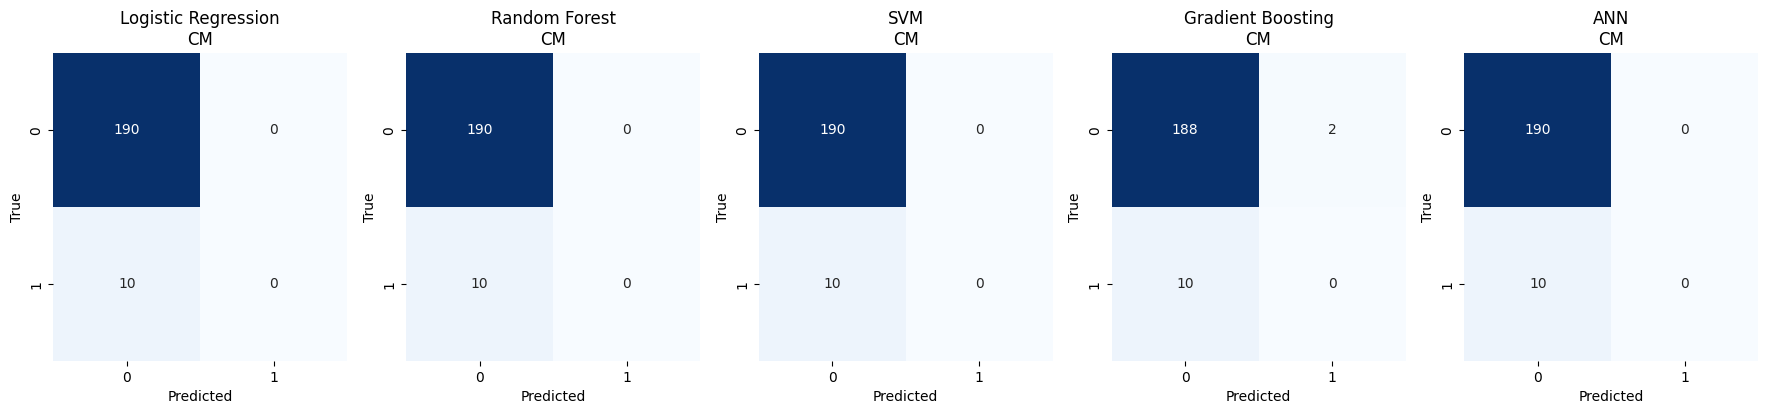

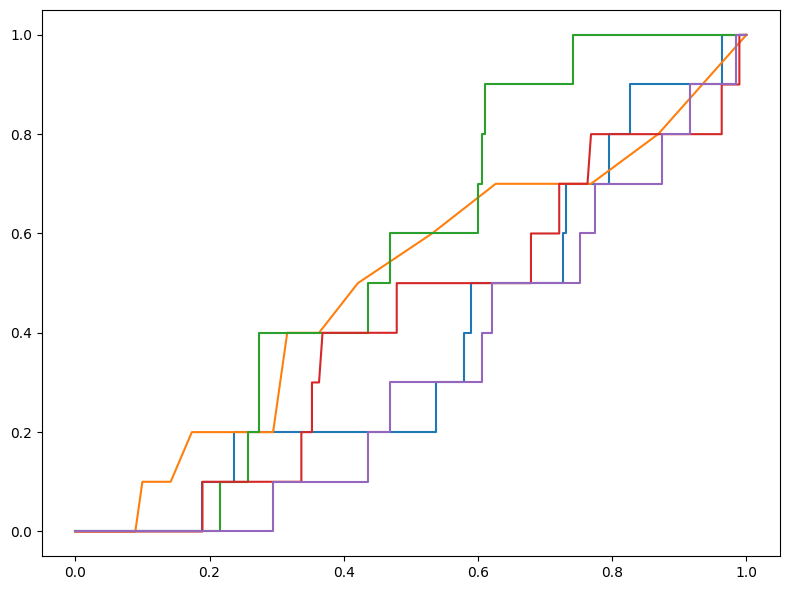

In [9]:
metrics_summary = []

# Plot setup
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
fig_roc, ax_roc = plt.subplots(figsize=(8, 6))

for idx, (name, preds) in enumerate(results.items()):
    y_pred = preds['y_pred']
    y_prob = preds['y_prob']

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    metrics_summary.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'AUC-ROC': auc
    })

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{name}\nCM')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('True')

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax_roc.plot(fpr, tpr, label=f'{name} (AUC = {auc:.2f})')

plt.tight_layout()
plt.show()

# Finish ROC plot
ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax_roc.set_title('ROC Curves Comparison')
ax_roc.set_xlabel('False Positive Rate')
ax_roc.set_ylabel('True Positive Rate')
ax_roc.legend()
plt.show()

### 5. Comparative Performance and Top 3 Models
We rank the models based on multiple dimensions of predictive performance to determine the Top 3 choices for stroke prediction.

In [10]:
summary_df = pd.DataFrame(metrics_summary)
# Rank by both AUC-ROC and F1-Score
summary_df['Rank_Score'] = summary_df['AUC-ROC'] + summary_df['F1-Score']
top_models = summary_df.sort_values(by='Rank_Score', ascending=False).head(3).copy()

print("=== Performance Matrix of All Models ===")
display(summary_df.drop(columns=['Rank_Score']))

print("\n=== Top 3 Models Selected for Stroke Risk Prediction Analysis ===")
display(top_models.drop(columns=['Rank_Score']))

=== Performance Matrix of All Models ===


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Logistic Regression,0.95,0.0,0.0,0.0,0.382632
1,Random Forest,0.95,0.0,0.0,0.0,0.500263
2,SVM,0.95,0.0,0.0,0.0,0.551579
3,Gradient Boosting,0.94,0.0,0.0,0.0,0.415789
4,ANN,0.95,0.0,0.0,0.0,0.327368



=== Top 3 Models Selected for Stroke Risk Prediction Analysis ===


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
2,SVM,0.95,0.0,0.0,0.0,0.551579
1,Random Forest,0.95,0.0,0.0,0.0,0.500263
3,Gradient Boosting,0.94,0.0,0.0,0.0,0.415789
